In [4]:
!pip install ultralytics

import os
import json
import shutil
import random
from PIL import Image
from ultralytics import YOLO

# 1. Output directory in Kaggle's writable space
BASE_DIR = "/kaggle/working/unified_dental_dataset"
for split in ["train", "val", "test"]:
    os.makedirs(f"{BASE_DIR}/images/{split}", exist_ok=True)
    os.makedirs(f"{BASE_DIR}/labels/{split}", exist_ok=True)

class_mapping = {
    0: "Inter-Radicular", 1: "Non-Odontogenic", 2: "Periapical",
    3: "Pericoronal", 4: "Caries", 5: "Deep Caries", 6: "Impacted"
}

# -------------------------------------------------------------
# 2. BULLETPROOF FILE DISCOVERY
# -------------------------------------------------------------
print("Scanning /kaggle/input/ for datasets...")
tufts_json = None
dentex_json = None
tufts_img_map = {}
dentex_img_map = {}

for root, dirs, files in os.walk('/kaggle/input'):
    for f in files:
        lname = f.lower()
        path = os.path.join(root, f)
        
        if lname == 'expert.json':
            tufts_json = path
        elif lname == 'train_quadrant_enumeration_disease.json':
            dentex_json = path
        elif lname.endswith(('.png', '.jpg', '.jpeg')):
            if "dentex" in path.lower() or "training_data" in path.lower():
                dentex_img_map[f] = path
            else:
                tufts_img_map[f] = path

print(f"Found Tufts labels: {tufts_json}")
print(f"Found DENTEX labels: {dentex_json}")
print(f"Indexed {len(tufts_img_map)} Tufts images and {len(dentex_img_map)} DENTEX images.")

# -------------------------------------------------------------
# 3. Harmonize Tufts Dataset
# -------------------------------------------------------------
print("\nProcessing Tufts Dataset...")
with open(tufts_json, "r") as f:
    tufts_data = json.load(f)

tufts_class_to_id = {
    "Inter-Radicular": 0, "Non-Odontogenic": 1, 
    "Periapical": 2, "Pericoronal": 3
}

tufts_samples = []
for entry in tufts_data:
    ext_id = entry.get("External ID")
    if not ext_id or ext_id not in tufts_img_map:
        continue
    img_path = tufts_img_map[ext_id]
    
    try:
        with Image.open(img_path) as im:
            img_w, img_h = im.size
    except Exception:
        continue
        
    bboxes = []
    objects = entry.get("Label", {}).get("objects", []) if isinstance(entry.get("Label"), dict) else []
    for obj in objects:
        title = obj.get("title", "").strip()
        if title not in tufts_class_to_id:
            continue
        cid = tufts_class_to_id[title]
        polys = obj.get("polygons", [])
        if not polys or polys == "none":
            continue
            
        xs, ys = [], []
        for poly in polys:
            for pt in poly:
                if len(pt) == 2:
                    xs.append(pt[0])
                    ys.append(pt[1])
        if not xs or not ys:
            continue
            
        xmin, xmax = min(xs), max(xs)
        ymin, ymax = min(ys), max(ys)
        
        xc = max(0.0, min(1.0, (xmin + xmax) / (2.0 * img_w)))
        yc = max(0.0, min(1.0, (ymin + ymax) / (2.0 * img_h)))
        bw = max(0.0, min(1.0, (xmax - xmin) / img_w))
        bh = max(0.0, min(1.0, (ymax - ymin) / img_h))
        
        if bw > 0 and bh > 0:
            bboxes.append(f"{cid} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n")
            
    tufts_samples.append((img_path, f"tufts_{ext_id}", bboxes))

# -------------------------------------------------------------
# 4. Harmonize DENTEX Dataset
# -------------------------------------------------------------
print("Processing DENTEX Dataset...")
with open(dentex_json, "r") as f:
    dentex_data = json.load(f)

dentex_images_dict = {img['id']: img for img in dentex_data['images']}
dentex_to_unified = {0: 4, 1: 5, 2: 2, 3: 6}
dentex_samples = {}

for ann in dentex_data.get("annotations", []):
    if "category_id_3" not in ann:
        continue
    img_id = ann["image_id"]
    if img_id not in dentex_images_dict:
        continue
    img_info = dentex_images_dict[img_id]
    fname = os.path.basename(img_info["file_name"])
    
    if fname not in dentex_img_map:
        continue
    img_path = dentex_img_map[fname]
    
    cid = dentex_to_unified.get(ann["category_id_3"])
    if cid is None:
        continue
        
    x_min, y_min, w, h = ann["bbox"]
    img_w, img_h = img_info["width"], img_info["height"]
    
    xc = max(0.0, min(1.0, (x_min + w / 2.0) / img_w))
    yc = max(0.0, min(1.0, (y_min + h / 2.0) / img_h))
    bw = max(0.0, min(1.0, w / img_w))
    bh = max(0.0, min(1.0, h / img_h))
    
    if bw > 0 and bh > 0:
        line = f"{cid} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n"
        prefixed = f"dentex_{fname}"
        if img_path not in dentex_samples:
            dentex_samples[img_path] = (prefixed, [])
        dentex_samples[img_path][1].append(line)

all_dentex_samples = [(p, item[0], item[1]) for p, item in dentex_samples.items()]

# -------------------------------------------------------------
# 5. Merge, Split (80/10/10), and Copy
# -------------------------------------------------------------
print("Partitioning and merging datasets...")
combined_samples = tufts_samples + all_dentex_samples
random.seed(42)
random.shuffle(combined_samples)

n_total = len(combined_samples)
n_train = int(n_total * 0.8)
n_val = int(n_total * 0.1)

splits = {
    "train": combined_samples[:n_train],
    "val": combined_samples[n_train:n_train + n_val],
    "test": combined_samples[n_train + n_val:]
}

for s_name, s_items in splits.items():
    for src_img, out_fname, bboxes in s_items:
        dst_img = f"{BASE_DIR}/images/{s_name}/{out_fname}"
        shutil.copy(src_img, dst_img)
        
        lbl_fname = os.path.splitext(out_fname)[0] + ".txt"
        dst_lbl = f"{BASE_DIR}/labels/{s_name}/{lbl_fname}"
        with open(dst_lbl, "w") as lf:
            lf.writelines(bboxes)

yaml_lines = [
    f"path: {BASE_DIR}",
    "train: images/train",
    "val: images/val",
    "test: images/test",
    "",
    "names:"
]
for k, v in class_mapping.items():
    yaml_lines.append(f"  {k}: {v}")

with open(f"{BASE_DIR}/data.yaml", "w") as yf:
    yf.write("\n".join(yaml_lines))

print(f"Data ready. Total labeled images mapped: {n_total}")

# -------------------------------------------------------------
# 6. Launch Training
# -------------------------------------------------------------
print("Starting YOLOv8s Training...")
model = YOLO('yolov8s.pt')

results = model.train(
    data=f"{BASE_DIR}/data.yaml",
    epochs=120,
    imgsz=1024,
    batch=16,
    device=0,
    workers=4,
    patience=25,
    mosaic=1.0,
    mixup=0.15,
    project="/kaggle/working/runs",
    name="dental_yolov8s_run"
)

Scanning /kaggle/input/ for datasets...
Found Tufts labels: /kaggle/input/datasets/tommyngx/the-tufts-dental-database-2022/Expert/Expert/expert.json
Found DENTEX labels: /kaggle/input/datasets/truthisneverlinear/dentex-challenge-2023/training_data/training_data/quadrant-enumeration-disease/train_quadrant_enumeration_disease.json
Indexed 2001 Tufts images and 1622 DENTEX images.

Processing Tufts Dataset...
Processing DENTEX Dataset...
Partitioning and merging datasets...
Data ready. Total labeled images mapped: 1678
Starting YOLOv8s Training...
Ultralytics 8.4.163 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/unified_dental_da

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/120       8.2G      2.443      3.513      2.152         62       1024: 100% ━━━━━━━━━━━━ 84/84 1.7it/s 50.4s0.5ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 3.4it/s 1.8s0.4s
                   all        167        406     0.0698      0.179      0.086     0.0627

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/120      8.05G      2.475      3.347      2.209         85       1024: 100% ━━━━━━━━━━━━ 84/84 1.6it/s 52.2s0.6ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 3.4it/s 1.8s0.4s
                   all        167        406      0.412     0.0999     0.0485     0.0404

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/120      8.13G      2.393      3.322      2.134         76       1024: 100% ━━━━━━━━━━━━ 84/84 1.6it/s 52.6s0.6ss
                 Class     Images  Insta

In [3]:
import os
import glob

print("Scanning for labels...")
jsons = glob.glob("/kaggle/input/**/*.json", recursive=True)
for j in jsons:
    # Only print the relevant ones so we don't spam the console
    if 'expert' in j.lower() or 'disease' in j.lower():
        print(f"✅ Found: {j}")

Scanning for labels...
✅ Found: /kaggle/input/datasets/tommyngx/the-tufts-dental-database-2022/Expert/Expert/expert.json
✅ Found: /kaggle/input/datasets/truthisneverlinear/dentex-challenge-2023/training_data/training_data/quadrant-enumeration-disease/train_quadrant_enumeration_disease.json


In [5]:
from ultralytics import YOLO

# Load the best weights from this run to continue learning, 
# rather than starting from scratch!
model = YOLO('/kaggle/working/runs/dental_yolov8s_run/weights/best.pt')

results = model.train(
    data="/kaggle/working/unified_dental_dataset/data.yaml",
    epochs=100,
    imgsz=1024,
    batch=16,
    device=0,
    workers=4,
    patience=20,
    
    # --- Surgical Augmentations for Small Objects ---
    mosaic=0.15,      # Barely use mosaic so cavities stay full size
    mixup=0.0,        # Turn off completely (cavities cannot be transparent)
    degrees=5.0,      # Reduce rotation to keep jawlines natural
    hsv_s=0.2,        # Reduce contrast shifting
    lr0=0.005,        # Slightly lower learning rate for fine-tuning
    
    project="/kaggle/working/runs",
    name="dental_yolov8s_fine_tuned"
)

Ultralytics 8.4.163 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/unified_dental_dataset/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.2, hsv_v=0.4, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/runs/dental_yolov8s_run/weights/best.pt, momentum=0.937, mosaic=0.15, 

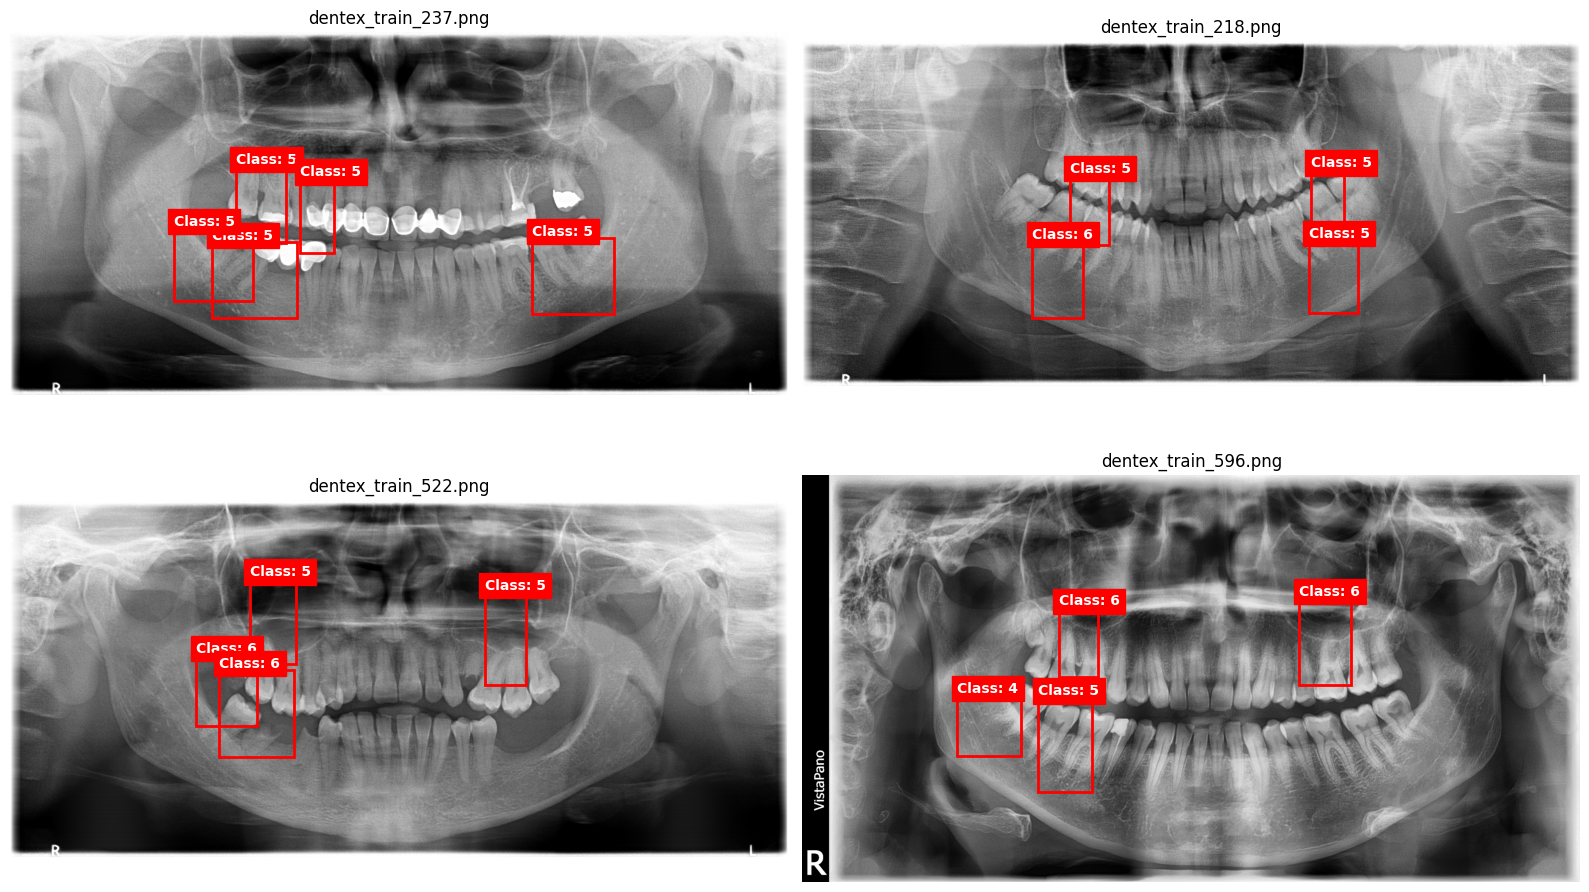

In [6]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import glob
import os
import random

# Grab 4 random DENTEX images from the training set
img_files = glob.glob("/kaggle/working/unified_dental_dataset/images/train/dentex_*.*")
random.shuffle(img_files)
img_files = img_files[:4]

fig, axs = plt.subplots(2, 2, figsize=(16, 10))
axs = axs.flatten()

for i, img_path in enumerate(img_files):
    img = Image.open(img_path)
    w, h = img.size
    axs[i].imshow(img, cmap='gray')
    
    # Locate the corresponding label file
    label_path = img_path.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'
    
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    class_id = int(parts[0])
                    xc, yc, bw, bh = map(float, parts[1:])
                    
                    # Convert YOLO normalized coordinates back to absolute pixels
                    xmin = (xc - bw / 2.0) * w
                    ymin = (yc - bh / 2.0) * h
                    box_w = bw * w
                    box_h = bh * h
                    
                    # Draw the bounding box
                    rect = patches.Rectangle((xmin, ymin), box_w, box_h, linewidth=2, edgecolor='red', facecolor='none')
                    axs[i].add_patch(rect)
                    axs[i].text(xmin, ymin - 8, f'Class: {class_id}', color='white', fontsize=10, backgroundcolor='red', fontweight='bold')
                    
    axs[i].set_title(os.path.basename(img_path))
    axs[i].axis('off')

plt.tight_layout()
plt.show()

In [8]:
from ultralytics import YOLO

# Reload the best baseline weights
model = YOLO('/kaggle/working/runs/dental_yolov8s_fine_tuned/weights/best.pt')

results = model.train(
    data="/kaggle/working/unified_dental_dataset/data.yaml",
    epochs=100,
    imgsz=1024,
    batch=16,
    device=0,
    workers=4,
    patience=20,
    
    # --- Loss Function Surgery (API Compatible) ---
    cls=5.0,          # 5x penalty for predicting "background" instead of the disease
    box=5.0,          # 5x penalty for drawing boxes that don't match the large tooth boundaries
    lr0=0.001,        # Very low learning rate so we don't accidentally wreck the Tufts classes
    
    # Keep augmentations completely disabled so the teeth are crystal clear
    mosaic=0.0,
    mixup=0.0,
    degrees=2.0,
    
    project="/kaggle/working/runs",
    name="dental_yolov8s_strict_loss"
)

Ultralytics 8.4.163 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=5.0, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=5.0, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/unified_dental_dataset/data.yaml, degrees=2.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/runs/dental_yolov8s_fine_tuned/weights/best.pt, momentum=0.937, mosaic

In [9]:
import os
import glob
import shutil
import random

BASE_DIR = "/kaggle/working/tufts_pure_dataset"

print("--- Scanning for Loki Silvres Dataset ---")

# 1. Map all images in the Kaggle input directory
all_images = glob.glob("/kaggle/input/**/*.jpg", recursive=True) + \
             glob.glob("/kaggle/input/**/*.png", recursive=True) + \
             glob.glob("/kaggle/input/**/*.jpeg", recursive=True)

# Isolate the Loki dataset images by excluding Tufts and DENTEX
loki_images = {os.path.splitext(os.path.basename(p))[0]: p for p in all_images if "tufts" not in p.lower() and "dentex" not in p.lower()}

# Isolate the Loki dataset label files (.txt)
loki_labels = [f for f in glob.glob("/kaggle/input/**/*.txt", recursive=True) if "tufts" not in f.lower() and "dentex" not in f.lower()]

print(f"Found {len(loki_labels)} YOLO label files in the new dataset.")

valid_samples = []

# 2. Extract only the Caries class and remap to Unified Class 4
for label_path in loki_labels:
    base_name = os.path.splitext(os.path.basename(label_path))[0]
    
    if base_name not in loki_images:
        continue
        
    img_path = loki_images[base_name]
    new_bboxes = []
    
    with open(label_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if not parts:
                continue
                
            class_id = parts[0]
            # Loki's Caries is Class 0. We only want this class.
            if class_id == "0":
                # Convert to Unified Class 4
                new_line = f"4 {' '.join(parts[1:])}\n"
                new_bboxes.append(new_line)
                
    if new_bboxes:
        valid_samples.append((img_path, f"loki_{base_name}", new_bboxes))

print(f"Extracted {len(valid_samples)} images containing tight Caries bounding boxes.")

# 3. Inject the clean samples into the existing Tufts splits
random.seed(42)
random.shuffle(valid_samples)

n_total = len(valid_samples)
n_train = int(n_total * 0.8)
n_val = int(n_total * 0.1)

splits = {
    "train": valid_samples[:n_train],
    "val": valid_samples[n_train:n_train + n_val],
    "test": valid_samples[n_train + n_val:]
}

for s_name, s_items in splits.items():
    img_dir = f"{BASE_DIR}/images/{s_name}"
    lbl_dir = f"{BASE_DIR}/labels/{s_name}"
    
    for src_img, out_fname, bboxes in s_items:
        dst_img = os.path.join(img_dir, f"{out_fname}{os.path.splitext(src_img)[1]}")
        shutil.copy(src_img, dst_img)
        
        dst_lbl = os.path.join(lbl_dir, f"{out_fname}.txt")
        with open(dst_lbl, "w") as f:
            f.writelines(bboxes)

print("Merge complete! The clean Caries data has been added to tufts_pure_dataset.")

--- Scanning for Loki Silvres Dataset ---
Found 0 YOLO label files in the new dataset.
Extracted 0 images containing tight Caries bounding boxes.
Merge complete! The clean Caries data has been added to tufts_pure_dataset.


In [11]:
import os

print("--- Inspecting Loki Silvres Dataset Structure ---")

# Find the exact folder name Kaggle assigned to it
loki_dir = None
for d in os.listdir('/kaggle/input'):
    if "dental" in d.lower() or "panoramic" in d.lower():
        # Exclude our known Tufts and DENTEX folders
        if "tufts" not in d.lower() and "dentex" not in d.lower():
            loki_dir = os.path.join('/kaggle/input', d)
            break

if loki_dir:
    print(f"Found Dataset Folder: {loki_dir}\n")
    
    # Walk through and print the first few files in each subfolder
    for root, dirs, files in os.walk(loki_dir):
        level = root.replace(loki_dir, '').count(os.sep)
        indent = ' ' * 4 * level
        print(f"{indent}📂 {os.path.basename(root)}/ ({len(files)} files)")
        
        # Print up to 3 file names as examples to see the extensions
        for f in files[:3]:
            print(f"{indent}    📄 {f}")
else:
    print("Could not find the dataset folder. Check the Input panel on the right.")

--- Inspecting Loki Silvres Dataset Structure ---
Could not find the dataset folder. Check the Input panel on the right.


In [19]:
import os

print("--- Listing ALL items in /kaggle/input/ ---")

for d in os.listdir('/kaggle/input'):
    folder_path = os.path.join('/kaggle/input', d)
    if os.path.isdir(folder_path):
        print(f"\n📂 {d}/")
        
        # List up to 5 top-level items
        for item in os.listdir(folder_path)[:5]:
            item_path = os.path.join(folder_path, item)
            
            if os.path.isdir(item_path):
                print(f"    📁 {item}/ (directory)")
                
                # Peek inside subdirectories
                try:
                    for sub_item in os.listdir(item_path)[:3]:
                        print(f"        📄 {sub_item}")
                except PermissionError:
                    pass
            else:
                print(f"    📄 {item}")

--- Listing ALL items in /kaggle/input/ ---

📂 notebooks/
    📁 lokisilvres/ (directory)
    📁 mohamedmagdyhekal/ (directory)
    📁 fanyekong/ (directory)

📂 datasets/
    📁 lokisilvres/ (directory)
        📄 dental-disease-panoramic-detection-dataset
    📁 tommyngx/ (directory)
        📄 the-tufts-dental-database-2022
    📁 truthisneverlinear/ (directory)


In [20]:
import os
import shutil
import random

BASE_DIR = "/kaggle/working/tufts_pure_dataset"

print("--- Bulletproof Scan for Loki Silvres Dataset ---")

loki_images = {}
loki_labels = []

# 1. Hard-scan every single file in /kaggle/input
for root, dirs, files in os.walk('/kaggle/input', followlinks=True):
    # Skip our known datasets so we only grab Loki's data
    if "tufts" in root.lower() or "dentex" in root.lower():
        continue
        
    for f in files:
        path = os.path.join(root, f)
        ext = f.lower()
        
        # Grab images
        if ext.endswith(('.png', '.jpg', '.jpeg')):
            base_name = os.path.splitext(f)[0]
            loki_images[base_name] = path
            
        # Grab YOLO labels
        elif ext.endswith('.txt') and f != "classes.txt":
            loki_labels.append(path)

print(f"Found {len(loki_labels)} YOLO label files.")
print(f"Found {len(loki_images)} corresponding images.")

valid_samples = []

# 2. Extract only Caries (Class 0) and remap to Unified Class 4
for label_path in loki_labels:
    base_name = os.path.splitext(os.path.basename(label_path))[0]
    
    if base_name not in loki_images:
        continue
        
    img_path = loki_images[base_name]
    new_bboxes = []
    
    try:
        with open(label_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if not parts: continue
                    
                class_id = parts[0]
                # Loki's Caries is Class 0. Extract only this class.
                if class_id == "0":
                    new_line = f"4 {' '.join(parts[1:])}\n"
                    new_bboxes.append(new_line)
                    
        # Only keep the image if it actually contains a Caries bounding box
        if new_bboxes:
            valid_samples.append((img_path, f"loki_{base_name}", new_bboxes))
            
    except Exception as e:
        continue

print(f"Extracted {len(valid_samples)} images containing tight Caries bounding boxes.")

# 3. Inject the clean samples into the existing Tufts splits
random.seed(42)
random.shuffle(valid_samples)

n_total = len(valid_samples)
n_train = int(n_total * 0.8)
n_val = int(n_total * 0.1)

splits = {
    "train": valid_samples[:n_train],
    "val": valid_samples[n_train:n_train + n_val],
    "test": valid_samples[n_train + n_val:]
}

for s_name, s_items in splits.items():
    img_dir = f"{BASE_DIR}/images/{s_name}"
    lbl_dir = f"{BASE_DIR}/labels/{s_name}"
    
    for src_img, out_fname, bboxes in s_items:
        dst_img = os.path.join(img_dir, f"{out_fname}{os.path.splitext(src_img)[1]}")
        shutil.copy(src_img, dst_img)
        
        dst_lbl = os.path.join(lbl_dir, f"{out_fname}.txt")
        with open(dst_lbl, "w") as f:
            f.writelines(bboxes)

print("Merge complete! The clean Caries data has been successfully injected.")

--- Bulletproof Scan for Loki Silvres Dataset ---
Found 13932 YOLO label files.
Found 13932 corresponding images.
Extracted 3065 images containing tight Caries bounding boxes.


FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/tufts_pure_dataset/images/train/loki_cropped_P-S-MANN_2023-10-20145003_1_png.rf.1b75498ab0b0285c76795ad703c1c34f.jpg'

In [21]:
import os
import json
import glob
import shutil
import random
from PIL import Image

BASE_DIR = "/kaggle/working/unified_clean_dataset"

# 1. Guarantee output directory structure exists
for split in ["train", "val", "test"]:
    os.makedirs(f"{BASE_DIR}/images/{split}", exist_ok=True)
    os.makedirs(f"{BASE_DIR}/labels/{split}", exist_ok=True)

class_mapping = {
    0: "Inter-Radicular",
    1: "Non-Odontogenic",
    2: "Periapical",
    3: "Pericoronal",
    4: "Caries"
}

# -------------------------------------------------------------
# 2. Extract Tufts Dataset (Classes 0-3)
# -------------------------------------------------------------
print("--- Processing Tufts Dataset ---")
tufts_json_matches = glob.glob("/kaggle/input/**/expert.json", recursive=True)
if not tufts_json_matches:
    raise FileNotFoundError("Could not find expert.json for Tufts dataset.")
tufts_json = tufts_json_matches[0]

tufts_img_map = {}
for root, dirs, files in os.walk('/kaggle/input', followlinks=True):
    if "dentex" in root.lower() or "panoramic" in root.lower() or "loki" in root.lower():
        continue
    for f in files:
        if f.lower().endswith(('.png', '.jpg', '.jpeg')):
            tufts_img_map[f] = os.path.join(root, f)

with open(tufts_json, "r") as f:
    tufts_data = json.load(f)

tufts_class_to_id = {
    "Inter-Radicular": 0,
    "Non-Odontogenic": 1,
    "Periapical": 2,
    "Pericoronal": 3
}

tufts_samples = []
for entry in tufts_data:
    ext_id = entry.get("External ID")
    if not ext_id or ext_id not in tufts_img_map:
        continue
    img_path = tufts_img_map[ext_id]

    try:
        with Image.open(img_path) as im:
            img_w, img_h = im.size
    except Exception:
        continue

    bboxes = []
    objects = entry.get("Label", {}).get("objects", []) if isinstance(entry.get("Label"), dict) else []
    for obj in objects:
        title = obj.get("title", "").strip()
        if title not in tufts_class_to_id:
            continue
        cid = tufts_class_to_id[title]
        polys = obj.get("polygons", [])
        if not polys or polys == "none":
            continue

        xs, ys = [], []
        for poly in polys:
            for pt in poly:
                if len(pt) == 2:
                    xs.append(pt[0])
                    ys.append(pt[1])
        if not xs or not ys:
            continue

        xmin, xmax = min(xs), max(xs)
        ymin, ymax = min(ys), max(ys)

        xc = max(0.0, min(1.0, (xmin + xmax) / (2.0 * img_w)))
        yc = max(0.0, min(1.0, (ymin + ymax) / (2.0 * img_h)))
        bw = max(0.0, min(1.0, (xmax - xmin) / img_w))
        bh = max(0.0, min(1.0, (ymax - ymin) / img_h))

        if bw > 0 and bh > 0:
            bboxes.append(f"{cid} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n")

    if bboxes:
        tufts_samples.append((img_path, f"tufts_{ext_id}", bboxes))

print(f"Extracted {len(tufts_samples)} valid Tufts images.")

# -------------------------------------------------------------
# 3. Extract Loki Silvres Dataset (Caries mapped to Class 4)
# -------------------------------------------------------------
print("--- Processing Loki Silvres Dataset ---")
loki_images = {}
loki_labels = []

for root, dirs, files in os.walk('/kaggle/input', followlinks=True):
    if "tufts" in root.lower() or "dentex" in root.lower():
        continue
    for f in files:
        path = os.path.join(root, f)
        ext = f.lower()
        if ext.endswith(('.png', '.jpg', '.jpeg')):
            base_name = os.path.splitext(f)[0]
            loki_images[base_name] = path
        elif ext.endswith('.txt') and f != "classes.txt":
            loki_labels.append(path)

loki_samples = []
for label_path in loki_labels:
    base_name = os.path.splitext(os.path.basename(label_path))[0]
    if base_name not in loki_images:
        continue
    img_path = loki_images[base_name]

    bboxes = []
    try:
        with open(label_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if not parts:
                    continue
                # Remap Loki Class 0 (Caries) -> Unified Class 4
                if parts[0] == "0":
                    bboxes.append(f"4 {' '.join(parts[1:])}\n")
        if bboxes:
            ext = os.path.splitext(img_path)[1]
            loki_samples.append((img_path, f"loki_{base_name}{ext}", bboxes))
    except Exception:
        continue

print(f"Extracted {len(loki_samples)} valid Caries images.")

# -------------------------------------------------------------
# 4. Merge, Split (80/10/10), and Copy
# -------------------------------------------------------------
all_samples = tufts_samples + loki_samples
random.seed(42)
random.shuffle(all_samples)

n_total = len(all_samples)
n_train = int(n_total * 0.8)
n_val = int(n_total * 0.1)

splits = {
    "train": all_samples[:n_train],
    "val": all_samples[n_train:n_train + n_val],
    "test": all_samples[n_train + n_val:]
}

for s_name, s_items in splits.items():
    img_dir = f"{BASE_DIR}/images/{s_name}"
    lbl_dir = f"{BASE_DIR}/labels/{s_name}"
    os.makedirs(img_dir, exist_ok=True)
    os.makedirs(lbl_dir, exist_ok=True)

    for src_img, out_fname, bboxes in s_items:
        # Guarantee extension matches source
        base_no_ext = os.path.splitext(out_fname)[0]
        ext = os.path.splitext(src_img)[1]
        dst_img = os.path.join(img_dir, f"{base_no_ext}{ext}")
        dst_lbl = os.path.join(lbl_dir, f"{base_no_ext}.txt")

        shutil.copy(src_img, dst_img)
        with open(dst_lbl, "w") as f:
            f.writelines(bboxes)

# Write data.yaml
yaml_lines = [
    f"path: {BASE_DIR}",
    "train: images/train",
    "val: images/val",
    "test: images/test",
    "",
    "names:"
]
for k, v in class_mapping.items():
    yaml_lines.append(f"  {k}: {v}")

with open(f"{BASE_DIR}/data.yaml", "w") as f:
    f.write("\n".join(yaml_lines))

print(f"Merge Complete! Total merged samples: {n_total}")
print(f"Config saved to {BASE_DIR}/data.yaml")

--- Processing Tufts Dataset ---
Extracted 340 valid Tufts images.
--- Processing Loki Silvres Dataset ---
Extracted 3065 valid Caries images.
Merge Complete! Total merged samples: 3405
Config saved to /kaggle/working/unified_clean_dataset/data.yaml


In [22]:
from ultralytics import YOLO

model = YOLO('yolov8s.pt')

results = model.train(
    data="/kaggle/working/unified_clean_dataset/data.yaml",
    epochs=60,
    imgsz=1024,
    batch=16,
    device=0,
    workers=4,
    patience=20,
    mosaic=0.5,
    mixup=0.0,
    degrees=5.0,
    project="/kaggle/working/runs",
    name="dental_clean_tufts_loki_p1"
)

Ultralytics 8.4.163 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/unified_clean_dataset/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=dental_clean_tufts_loki_p1,

In [23]:
from ultralytics import YOLO

# Load the checkpoint that achieved 60% Caries recall
model = YOLO('/kaggle/working/runs/dental_clean_tufts_loki_p1/weights/best.pt')

results = model.train(
    data="/kaggle/working/unified_clean_dataset/data.yaml",
    epochs=35,
    imgsz=1024,
    batch=16,
    device=0,
    workers=4,
    patience=0,        # Disable early stopping so it completes the full learning schedule
    mosaic=0.0,        # Turn OFF mosaic so it trains on full, clean panoramic crops
    mixup=0.0,
    lr0=0.002,         # Warm start at a lower learning rate
    lrf=0.01,          # Decays smoothly down to 0.00002
    close_mosaic=0,
    project="/kaggle/working/runs",
    name="dental_clean_tufts_loki_p2"
)

Ultralytics 8.4.163 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/unified_clean_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=35, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/runs/dental_clean_tufts_loki_p1/weights/best.pt, momentum=0.937, mosaic=0

In [25]:
from IPython.display import FileLink

# Generate direct browser download link for the best model weights
FileLink(r'runs/dental_clean_tufts_loki_p2/weights/best.pt')

/kaggle/working/runs/dental_clean_tufts_loki_p2/weights/best.pt